# Try Qdislib in 5 minutes

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bsc-wdc/qdislib/blob/main/notebooks/Qdislib_try_it.ipynb) [![Open in Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/bsc-wdc/qdislib/main?labpath=notebooks/Qdislib_try_it.ipynb)

What Qdislib does, in a few minutes. You will build a small circuit, follow four steps (find the cut, generate the subcircuits, run them, reconstruct), then compare the four cutting methods of the [SC poster](https://qdislib.readthedocs.io/en/latest/poster.html).

It runs in two places:

- **Binder or Docker**, with PyCOMPSs: the subcircuits run as parallel tasks, and at the end you see the task graph.
- **Colab or your own laptop**, without PyCOMPSs: the same cells run one after another, with the same results, and the first and last cells say so.

Run each cell with **Shift + Enter**. The results stored here come from a real run under COMPSs, in this notebook's Binder image.

In [1]:
# Installs Qdislib on Colab; does nothing on Binder or where it is installed.
# It does not import Qdislib: under PyCOMPSs that has to wait until the runtime starts.
import importlib.util

if importlib.util.find_spec("Qdislib") is None:
    %pip install -q "qdislib[qiskit]>=2.0"

In [2]:
# Start PyCOMPSs if it is here. graph=True records the task graph;
# cpu_affinity="disabled" skips CPU pinning, so it runs the same on any laptop or cloud VM.
try:
    import pycompss.interactive as ipycompss
    ipycompss.start(graph=True, cpu_affinity="disabled")
    under_compss = True
except ImportError:
    under_compss = False
    print("PyCOMPSs is not installed here: the subcircuits will run one after another, with the same results.")

PyCOMPSs runtime started.


## A circuit to cut

Five qubits joined by a chain of CZ gates. We estimate `<ZZZZZ>`.

In [3]:
%matplotlib inline
%config InlineBackend.figure_formats = ["png"]
import logging

from qiskit import QuantumCircuit
import Qdislib as qd
from Qdislib.utils.runtime import compss_wait_on

logging.getLogger("qiskit").setLevel(logging.WARNING)  # hide Qiskit's compiler log lines


def example_circuit():
    qc = QuantumCircuit(5)
    qc.ry(0.8, 0)
    qc.cz(0, 1)
    qc.ry(0.5, 1)
    qc.cz(1, 2)
    qc.ry(0.6, 2)
    qc.cz(2, 3)
    qc.ry(0.4, 3)
    qc.cz(3, 4)
    qc.rx(0.3, 4)
    return qc


circuit = example_circuit()
print(circuit.draw(fold=80))

     ┌─────────┐                                                        
q_0: ┤ Ry(0.8) ├─■──────────────────────────────────────────────────────
     └─────────┘ │ ┌─────────┐                                          
q_1: ────────────■─┤ Ry(0.5) ├─■────────────────────────────────────────
                   └─────────┘ │ ┌─────────┐                            
q_2: ──────────────────────────■─┤ Ry(0.6) ├─■──────────────────────────
                                 └─────────┘ │ ┌─────────┐              
q_3: ────────────────────────────────────────■─┤ Ry(0.4) ├─■────────────
                                               └─────────┘ │ ┌─────────┐
q_4: ──────────────────────────────────────────────────────■─┤ Rx(0.3) ├
                                                             └─────────┘


## Step 1: identify what to cut

`find_cut` searches the circuit graph. Here we ask for a **wire cut**, method (c) on the poster.

cut: [('CZ_4', 'RY_5')]


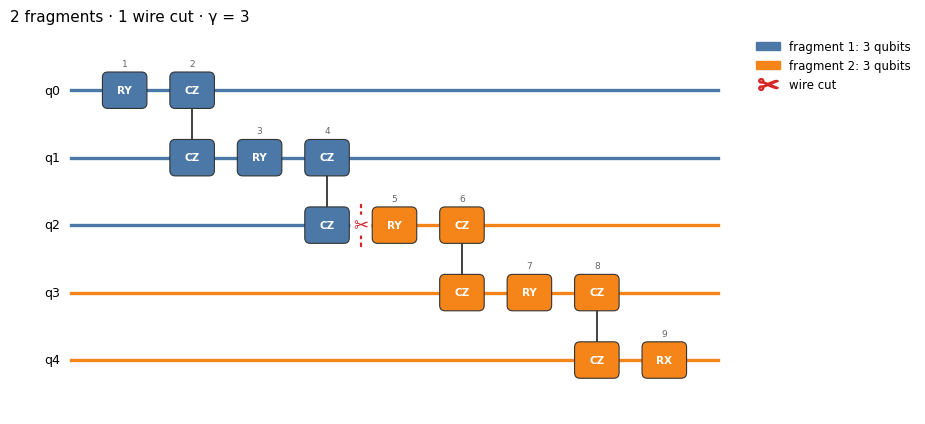

In [4]:
cut = qd.find_cut(circuit, gate_cut=False, wire_cut=True)
print("cut:", cut)
qd.draw_cut(circuit, cut);

## Step 2: generate the subcircuits

The cut leaves **2 fragments**. In general each wire cut has 8 terms, so 8 x 2 = 16 small subcircuits, as the poster counts.

This one has 12. It is a **golden cut point**: the state before the cut is real (only `ry` and `cz`), so its `Y` terms are zero and Qdislib leaves them out, automatically and exactly: 6 x 2 = 12.

In [5]:
subcircuits = qd.wire_cutting_subcircuits(circuit, cut)
print(subcircuits)
print("number of subcircuits:", len(subcircuits))

complex_state = example_circuit()
complex_state.rx(0.2, 0)    # a complex gate before the cut: not golden, the poster's 8 x 2
print("with a complex gate before the cut:", len(qd.wire_cutting_subcircuits(complex_state, cut)))

<CutCircuits: 12 subcircuits, 2 fragments, wire [('CZ_4', 'RY_5')], gamma 3, observable ZZZZZ>
number of subcircuits: 12
with a complex gate before the cut: 16


## Step 3: execute them

Under PyCOMPSs each `expectation_value` is a **task**: building this list submits all of them at once, and the runtime runs them on the available cores. On MareNostrum 5 they can go across nodes, GPUs or a QPU. Without PyCOMPSs, they run here one by one.

In [6]:
values = [qd.expectation_value(s) for s in subcircuits]
print(type(values[0]).__name__)

Future


## Step 4: reconstruct

`reconstruct` combines the pieces with their coefficients into the expectation value of the **original** circuit.

In [7]:
result = subcircuits.reconstruct(values)
exact = qd.analytical_solution(circuit, "ZZZZZ")

print(f"reconstructed from subcircuits: {result:+.4f}")
print(f"exact:                          {exact:+.4f}")
print(f"absolute error:                 {abs(result - exact):.4f}   (1024 shots per subcircuit)")

reconstructed from subcircuits: +0.4481
exact:                          +0.4440
absolute error:                 0.0040   (1024 shots per subcircuit)


## The four methods on the poster

The same circuit, one cut each. The poster's table gives the general count; two of them are lower on this circuit, because 2.0 leaves out the `Y` terms of a golden cut point.

| | Method | Poster, per `k` cuts | Here (`k = 1`) | Why |
|---|---|---|---|---|
| (a) | gate cut, mid-circuit measures | `6^k x 2` | 12 | |
| (b) | gate cut, Hadamard test | `6^k x 2` | 12 | |
| (c) | wire cut | `8^k x 2` | 12 | golden: 6 terms, not 8 |
| (d) | optimized wire cut | `3^k + 4^k` | 5 | golden: 2 + 3, not 3 + 4 |

The values agree with the exact one up to shot noise. Fewer circuits means less work.

In [8]:
gate_cut = qd.find_cut(circuit, gate_cut=True, wire_cut=False, seed=0)    # seed: the same cut every run
print("gate cut:", gate_cut)


def run(subs):
    """Run every subcircuit (a task under PyCOMPSs), then reconstruct."""
    return len(subs), subs.reconstruct([qd.expectation_value(s, shots=8192, seed=i) for i, s in enumerate(subs)])


methods = {
    "(a) gate cut":          run(qd.gate_cutting_subcircuits(circuit, gate_cut)),
    "(b) gate, Hadamard":    run(qd.gate_cutting_hadamard_subcircuits(circuit, gate_cut)),
    "(c) wire cut":          run(qd.wire_cutting_subcircuits(circuit, cut)),
    "(d) optimized wire":    run(qd.wire_cutting_subcircuits(circuit, cut, optimized=True)),
}

print(f"{'method':<22}{'subcircuits':>12}{'result':>10}{'error':>9}")
for name, (count, value) in methods.items():
    value = compss_wait_on(value)
    print(f"{name:<22}{count:>12}{value:>+10.4f}{abs(value - exact):>9.4f}")
print(f"{'exact':<22}{'':>12}{exact:>+10.4f}")

gate cut: ['CZ_4']


method                 subcircuits    result    error
(a) gate cut                    12   +0.4491   0.0050
(b) gate, Hadamard              12   +0.4399   0.0042
(c) wire cut                    12   +0.4431   0.0009
(d) optimized wire               5   +0.4453   0.0013
exact                                +0.4440


And how the count grows with the number of cuts `k`, from `qd.cutting_overhead`, which runs nothing. The circuit has complex gates, so nothing is golden. The Hadamard cut and the optimized wire cut share work between cuts by default, `joint=True`; with `joint=False` the counts are the poster's formulas.

In [9]:
def between_blocks(k):
    """Two blocks of k + 1 qubits with complex gates, joined by k CZ gates."""
    qc = QuantumCircuit(2 * k + 2)
    qc.rx(0.4, range(2 * k + 2))
    last = {}
    for block in (0, k + 1):
        for q in range(block, block + k):
            qc.cz(q, q + 1)
            last[q] = last[q + 1] = len(qc.data)
    gates, wires = [], []
    for q in range(k):
        qc.cz(q, k + 1 + q)
        gates.append(f"CZ_{len(qc.data)}")
        wires.append((f"CZ_{last[q]}", f"CZ_{len(qc.data)}"))
    return qc, gates, wires


print(f"{'k':>2}{'(a) 6^k x 2':>13}{'(b) 6^k x 2':>13}{'(c) 8^k x 2':>13}{'(d) 3^k + 4^k':>15}{'(b) joint':>11}{'(d) joint':>11}")
for k in (1, 2, 3, 4):
    qc, gates, wires = between_blocks(k)
    count = lambda spec, **options: qd.cutting_overhead(qc, spec, **options)["subcircuits"]
    print(f"{k:>2}{count({'gate': gates}):>13}{count({'hadamard': gates}, joint=False):>13}{count({'wire': wires}):>13}"
          f"{count({'wire': wires}, optimized=True, joint=False):>15}{count({'hadamard': gates}):>11}{count({'wire': wires}, optimized=True):>11}")

 k  (a) 6^k x 2  (b) 6^k x 2  (c) 8^k x 2  (d) 3^k + 4^k  (b) joint  (d) joint
 1           12           12           16              7         12          7
 2           72           72          128             25         56         21
 3          432          432         1024             91        240         73
 4         2592         2592         8192            337        992        273


## What PyCOMPSs did

Under PyCOMPSs this cell stops the runtime, waiting for every task, and draws the task graph: each subcircuit is an independent node, and nothing links them until the reconstruction, which is why they scale out.

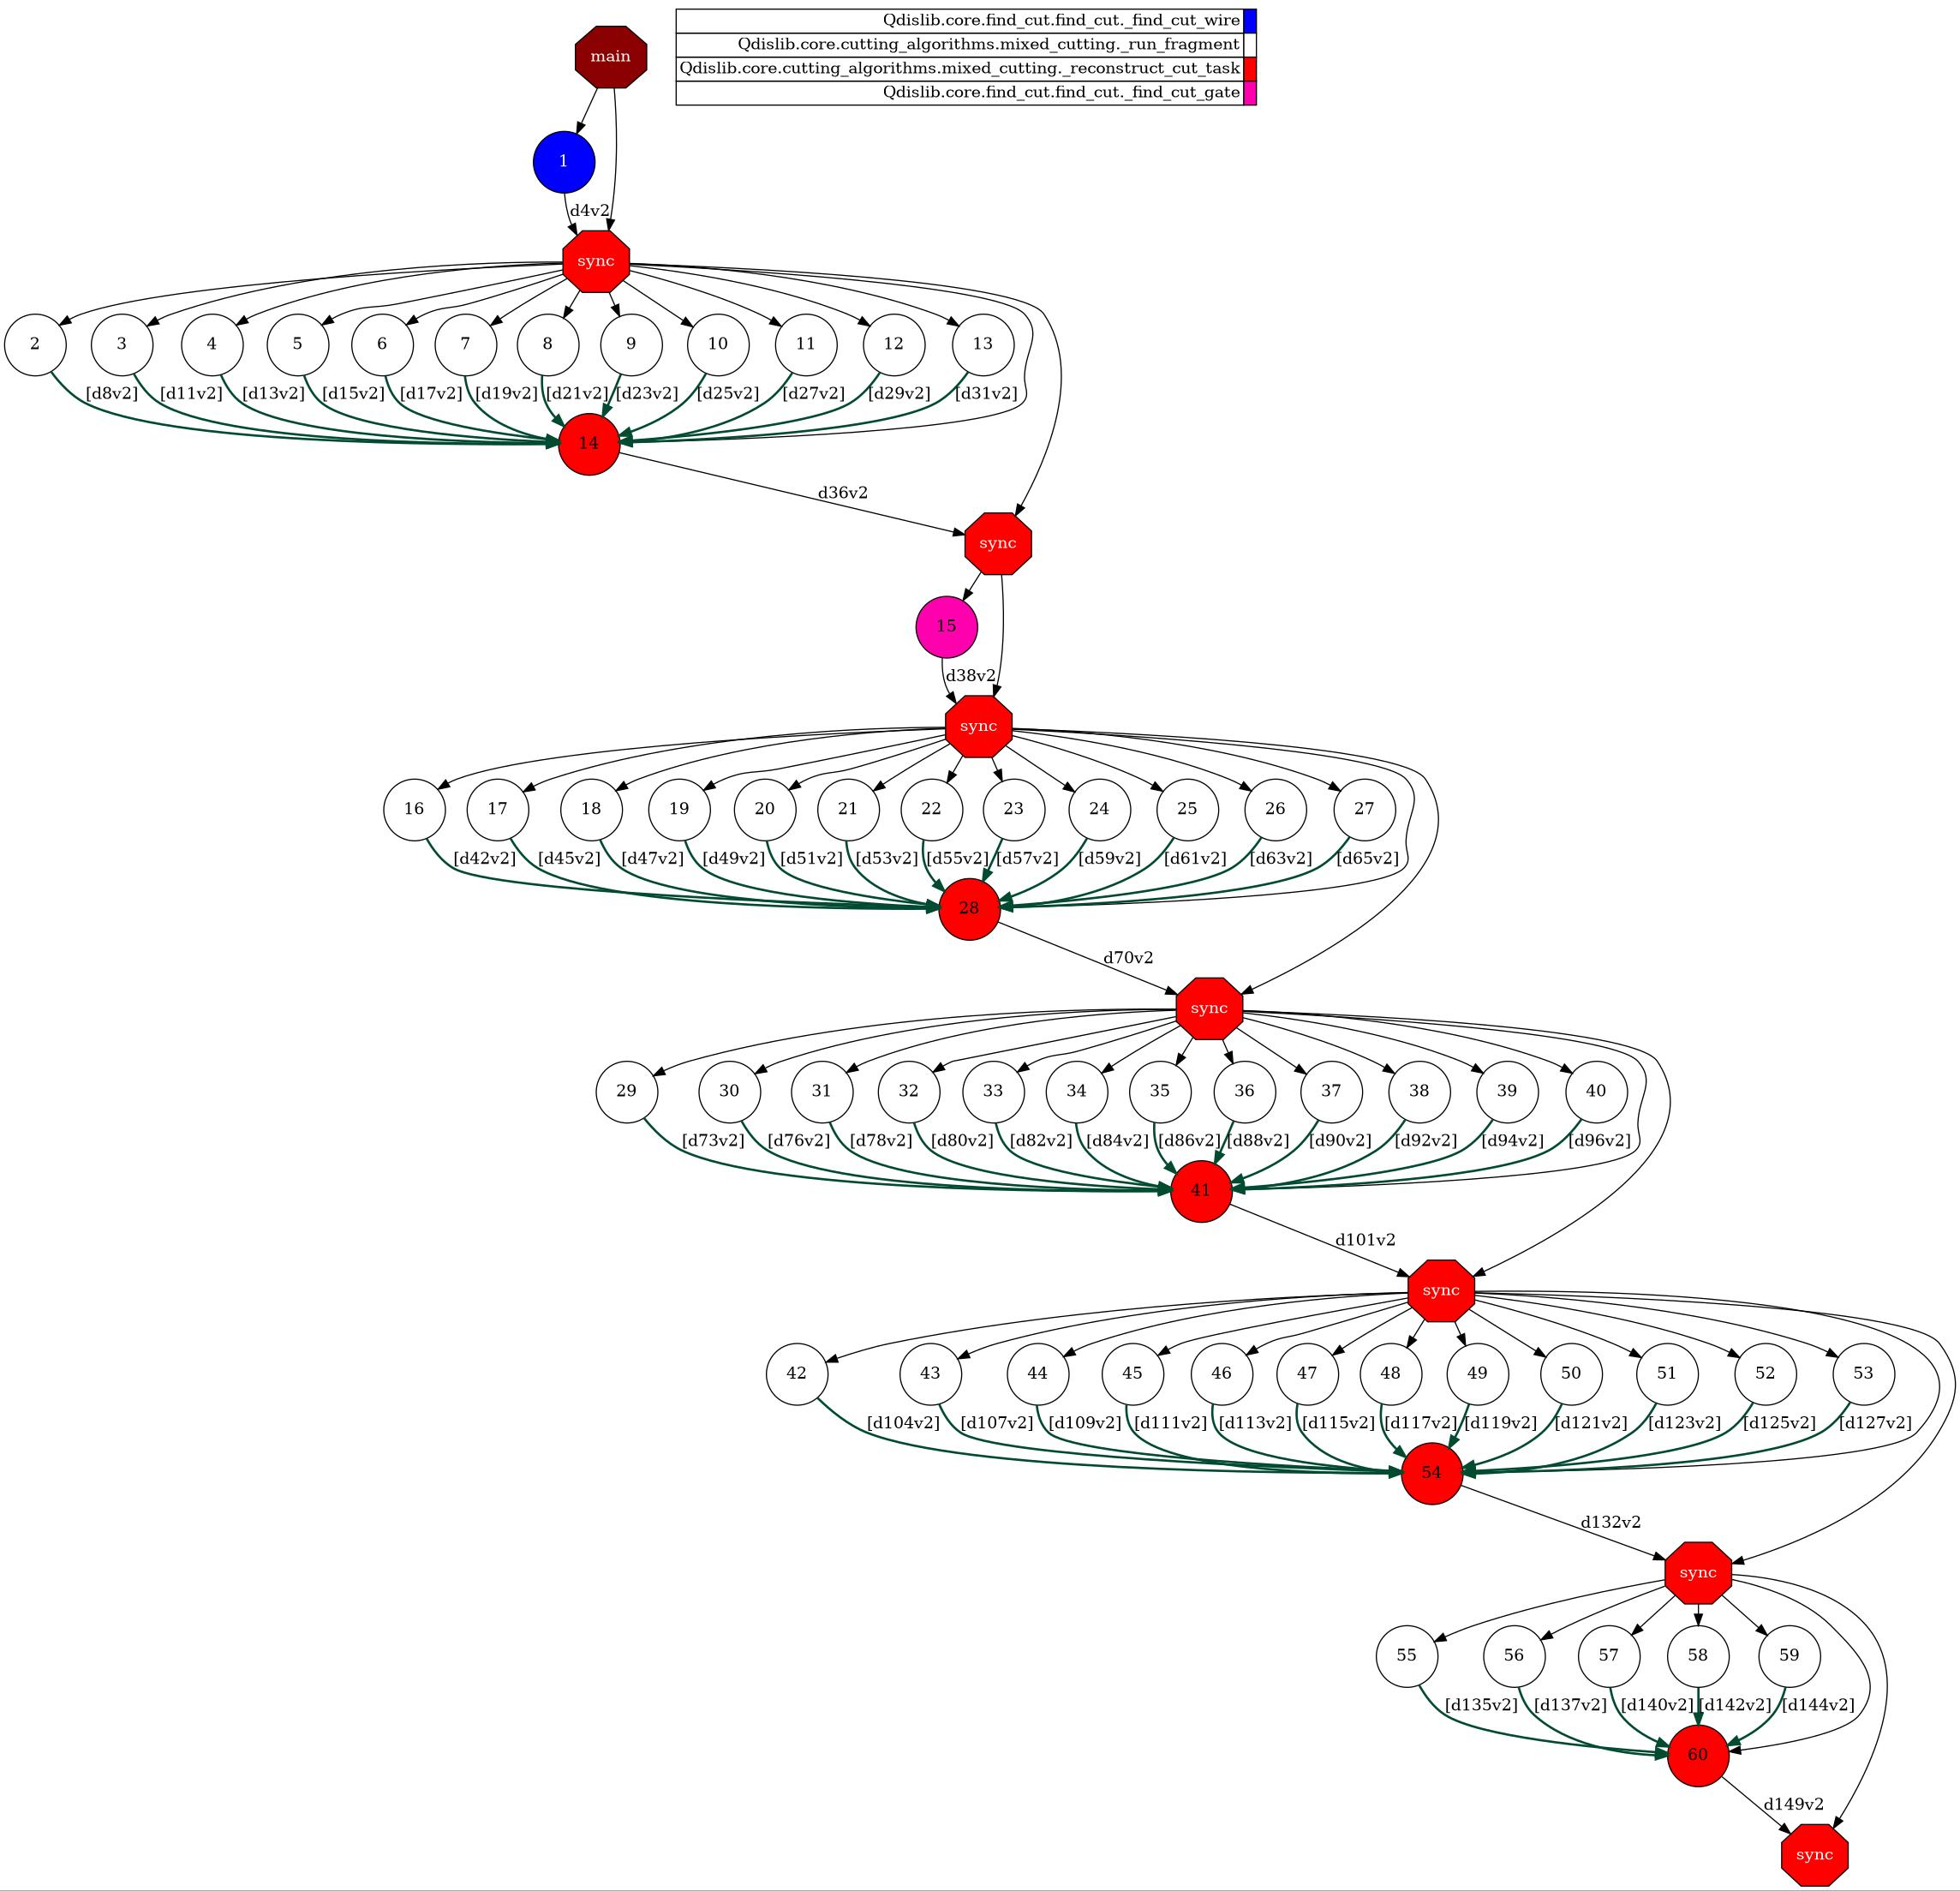

In [10]:
if under_compss:
    ipycompss.stop(sync=True)
    ipycompss.complete_task_graph(fit=True)
else:
    print("No task graph here: PyCOMPSs is not installed. Open this notebook on Binder to see it.")

## Next steps

* Install: `pip install "qdislib[qiskit]"`, or `uv pip install "qdislib[qiskit]"`. It runs serially as it is; for parallel runs add [PyCOMPSs](https://compss-doc.readthedocs.io/en/stable/Sections/01_Installation_Configuration.html).
* Documentation: [qdislib.readthedocs.io](https://qdislib.readthedocs.io), with the [learning path](https://qdislib.readthedocs.io/en/latest/examples.html)
* Source code: [github.com/bsc-wdc/qdislib](https://github.com/bsc-wdc/qdislib)
* Paper: [arXiv:2505.01184](https://arxiv.org/abs/2505.01184)